# Olist E-Commerce Customer Retention Analysis

## 1. Project Introduction

### Project Objective
This project analyzes the Brazilian Olist e-commerce dataset to understand order behavior, assess data quality, explore purchasing trends, and identify opportunities to improve customer retention.

### Business Questions
1. What is the overall distribution of order statuses?
2. How has order volume changed over time?
3. How many unique customers placed delivered orders?
4. What proportion of customers placed only one delivered order versus multiple delivered orders?
5. What data-quality limitations should be considered before drawing business conclusions?

### Technology Stack
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Jupyter Notebook
- SQL and Power BI for downstream analysis

### Workflow
1. Load and inspect the raw data.
2. Validate missing values, duplicates, and data types.
3. Analyze order status distribution.
4. Explore monthly order trends.
5. Measure customer purchasing behavior.
6. Summarize findings and prepare for cohort and RFM analysis.


## 2. Dataset Overview

The Olist Brazilian E-Commerce dataset contains order-level records and related customer information. This notebook begins by inspecting the orders dataset to understand its structure, completeness, and suitability for customer retention analysis.

### Dataset Scope
- **Primary table:** Orders
- **Grain:** One row per order
- **Key identifier:** `order_id`
- **Customer identifier:** `customer_id`
- **Order timestamp:** `order_purchase_timestamp`
- **Order outcome:** `order_status`

The customer mapping table will be used later to identify unique customers across multiple orders.


In [44]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Project paths
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"

# Load orders dataset
orders = pd.read_csv(RAW_DATA / "olist_orders_dataset.csv")

print("Orders shape:", orders.shape)
display(orders.head())


Orders shape: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


## 3. Data Quality Assessment

Data quality assessment is an important step before exploratory data analysis.

### Objectives
- Inspect column names and data types.
- Identify missing values and calculate their percentages.
- Check duplicate order identifiers and duplicate records.
- Determine which timestamp columns require conversion.
- Document data-quality limitations before further analysis.

### Validation Approach
Missing values will be quantified rather than automatically removed. Order identifiers will be checked for uniqueness, while missing delivery timestamps will be investigated in the context of order status.


In [45]:
print("Dataset dimensions:", orders.shape)

print("\nColumn names:")
print(orders.columns.tolist())

print("\nData types:")
display(orders.dtypes.to_frame(name="Data Type"))

print("\nDataset information:")
orders.info()


Dataset dimensions: (99441, 8)

Column names:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

Data types:


,Data Type
order_id,str
customer_id,str
order_status,str
order_purchase_timestamp,str
order_approved_at,str
order_delivered_carrier_date,str
order_delivered_customer_date,str
order_estimated_delivery_date,str



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [46]:
missing_summary = pd.DataFrame({
    "Missing Count": orders.isna().sum(),
    "Missing Percentage": (orders.isna().mean() * 100).round(2)
})
display(missing_summary.sort_values("Missing Percentage", ascending=False))

print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Unique order IDs:", orders["order_id"].nunique())
print("Duplicate complete rows:", orders.duplicated().sum())


,Missing Count,Missing Percentage
order_delivered_customer_date,2965,2.98
order_delivered_carrier_date,1783,1.79
order_approved_at,160,0.16
order_id,0,0.00
order_purchase_timestamp,0,0.00
order_status,0,0.00
customer_id,0,0.00
order_estimated_delivery_date,0,0.00


Duplicate order IDs: 0
Unique order IDs: 99441
Duplicate complete rows: 0


## 4. Order Status Distribution

This section examines the distribution of orders across statuses, including delivered, shipped, canceled, unavailable, and other recorded outcomes.

Understanding order status helps establish the scope for customer retention analysis. The primary retention analysis focuses on delivered orders so that customer purchase frequency is based on completed deliveries.


In [47]:
status_summary = (
    orders["order_status"]
    .value_counts(dropna=False)
    .rename_axis("Order Status")
    .reset_index(name="Order Count")
)
status_summary["Percentage"] = (status_summary["Order Count"] / len(orders) * 100).round(2)
display(status_summary)


,Order Status,Order Count,Percentage
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


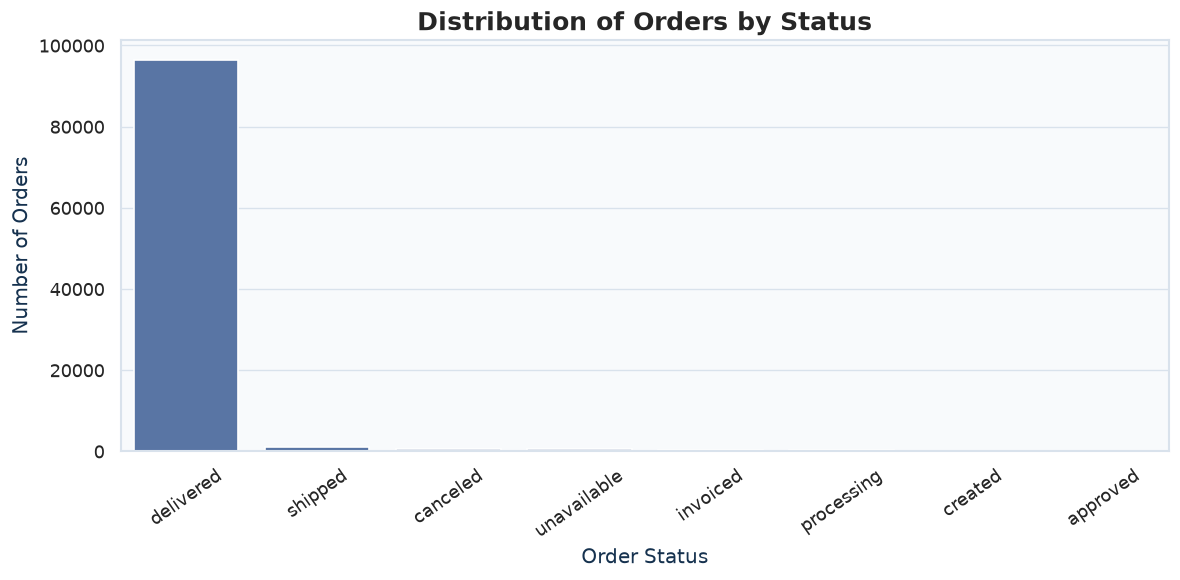

In [48]:
plt.figure(figsize=(10, 5))
sns.barplot(data=status_summary, x="Order Status", y="Order Count")
plt.title("Distribution of Orders by Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()


## 5. Monthly Order Trend

This section examines how order volume changes over time. Purchase timestamps are converted to datetime values and grouped into calendar months. Both all orders and delivered orders are displayed to distinguish overall activity from completed deliveries.


In [49]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)
orders["order_month"] = (
    orders["order_purchase_timestamp"].dt.to_period("M").dt.to_timestamp()
)

monthly_orders = (
    orders.groupby("order_month")
    .agg(
        total_orders=("order_id", "nunique"),
        delivered_orders=("order_status", lambda x: (x == "delivered").sum())
    )
    .reset_index()
)
display(monthly_orders.head())


,order_month,total_orders,delivered_orders
0,2016-09-01,4,1
1,2016-10-01,324,265
2,2016-12-01,1,1
3,2017-01-01,800,750
4,2017-02-01,1780,1653


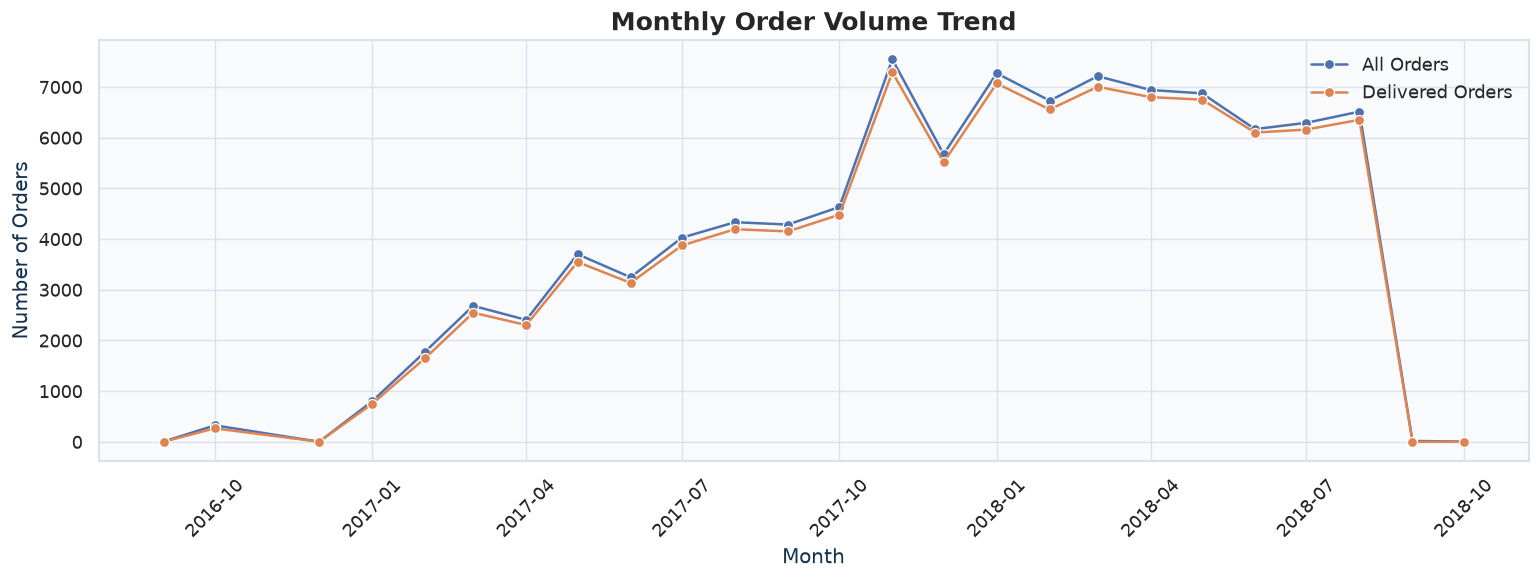

In [50]:
plt.figure(figsize=(13, 5))
sns.lineplot(data=monthly_orders, x="order_month", y="total_orders", marker="o", label="All Orders")
sns.lineplot(data=monthly_orders, x="order_month", y="delivered_orders", marker="o", label="Delivered Orders")
plt.title("Monthly Order Volume Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


In [51]:
print("Earliest purchase date:", orders["order_purchase_timestamp"].min())
print("Latest purchase date:", orders["order_purchase_timestamp"].max())
display(monthly_orders.tail(8))


Earliest purchase date: 2016-09-04 21:15:19
Latest purchase date: 2018-10-17 17:30:18


,order_month,total_orders,delivered_orders
17,2018-03-01,7211,7003
18,2018-04-01,6939,6798
19,2018-05-01,6873,6749
20,2018-06-01,6167,6099
21,2018-07-01,6292,6159
22,2018-08-01,6512,6351
23,2018-09-01,16,0
24,2018-10-01,4,0


### Monthly Trend — Initial Interpretation

Monthly order volume increased substantially during 2017 and remained comparatively high through much of 2018.

**Data-quality consideration:** A sharp decline in the final months should not automatically be interpreted as a business decline. Check the maximum purchase timestamp and whether the final calendar months are complete before drawing conclusions.


## 6. Customer Purchasing Behavior

This section measures one-time and repeat purchasing among customers with delivered orders. The `customer_unique_id` field is used to identify the same underlying customer across different customer records.


In [52]:
customers = pd.read_csv(RAW_DATA / "olist_customers_dataset.csv")

delivered = orders[orders["order_status"] == "delivered"].copy()

delivered_customer_orders = delivered.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

customer_purchase_counts = (
    delivered_customer_orders.groupby("customer_unique_id")["order_id"].nunique()
)

total_customers = customer_purchase_counts.size
one_time_customers = (customer_purchase_counts == 1).sum()
repeat_customers = (customer_purchase_counts >= 2).sum()
repeat_customer_rate = repeat_customers / total_customers * 100
one_time_customer_share = one_time_customers / total_customers * 100

print(f"Delivered orders: {len(delivered):,}")
print(f"Unique purchasing customers: {total_customers:,}")
print(f"One-time customers: {one_time_customers:,}")
print(f"Repeat customers: {repeat_customers:,}")
print(f"Repeat customer rate: {repeat_customer_rate:.2f}%")
print(f"One-time customer share: {one_time_customer_share:.2f}%")


Delivered orders: 96,478
Unique purchasing customers: 93,358
One-time customers: 90,557
Repeat customers: 2,801
Repeat customer rate: 3.00%
One-time customer share: 97.00%


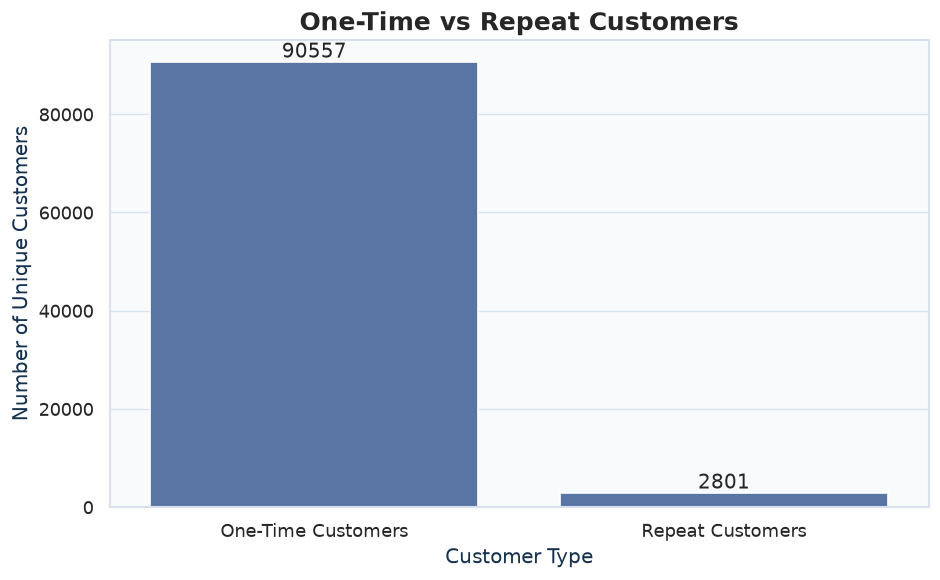

In [53]:
customer_summary = pd.DataFrame({
    "Customer Type": ["One-Time Customers", "Repeat Customers"],
    "Customer Count": [one_time_customers, repeat_customers]
})

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=customer_summary, x="Customer Type", y="Customer Count")
ax.bar_label(ax.containers[0], fmt="%.0f")
plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Unique Customers")
plt.tight_layout()
plt.show()


## 7. Customer Purchase Frequency Distribution

This section shows how many customers made one, two, three, or more delivered purchases. It provides additional context beyond the overall repeat-customer rate.


In [54]:
frequency_distribution = (
    customer_purchase_counts.value_counts()
    .sort_index()
    .rename_axis("Delivered Orders per Customer")
    .reset_index(name="Customer Count")
)
display(frequency_distribution.head(15))


,Delivered Orders per Customer,Customer Count
0,1,90557
1,2,2573
2,3,181
3,4,28
4,5,9
5,6,5
6,7,3
7,9,1
8,15,1


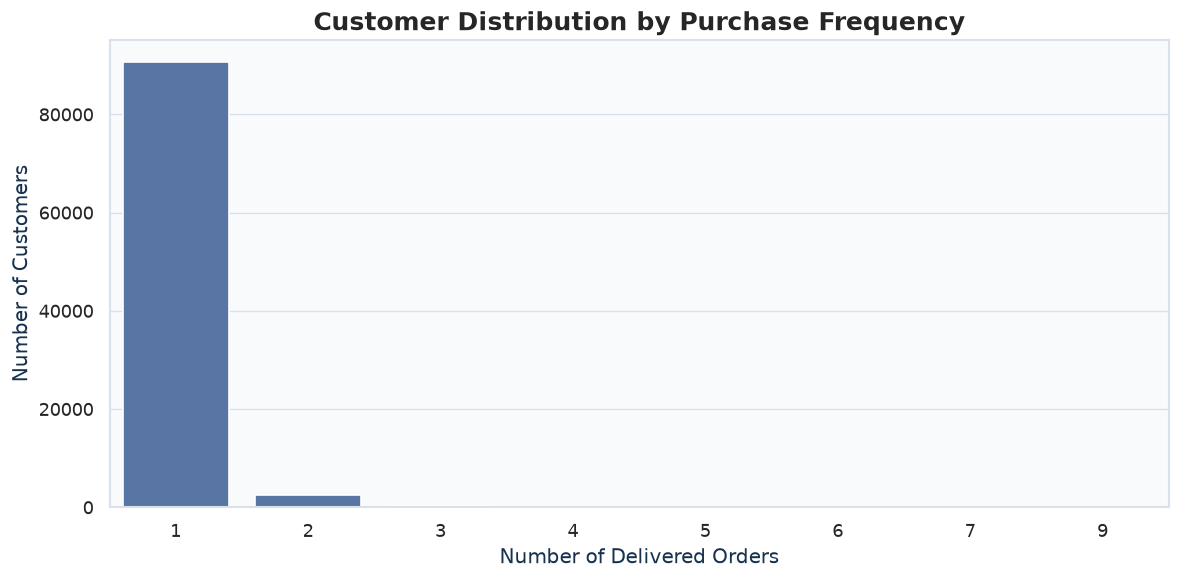

In [55]:
top_frequencies = frequency_distribution[
    frequency_distribution["Delivered Orders per Customer"] <= 10
]

plt.figure(figsize=(10, 5))
sns.barplot(data=top_frequencies, x="Delivered Orders per Customer", y="Customer Count")
plt.title("Customer Distribution by Purchase Frequency")
plt.xlabel("Number of Delivered Orders")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


## 8. Key Findings and Business Implications

### Data Quality
- The orders dataset contains 99,441 records and 8 columns.
- No duplicate order IDs were found.
- Several timestamp columns contain missing values.
- Timestamp conversion is necessary for reliable time-based analysis.

### Order Trends
- Delivered orders account for approximately 97.02% of all order records.
- Monthly order volume increased substantially during 2017 and remained comparatively high through much of 2018.
- The final months require a completeness check before interpreting the observed decline.

### Customer Purchasing Behavior
- The analysis should identify approximately 93,358 unique purchasing customers with delivered orders.
- Approximately 90,557 customers placed only one delivered order.
- Approximately 2,801 customers placed at least two delivered orders.
- The repeat customer rate is approximately 3.00%.

### Business Implications
The large one-time customer population represents an opportunity to investigate repeat-purchase behavior. Potential actions include post-purchase communication, relevant product recommendations, and targeted retention campaigns. Their effectiveness must be evaluated using subsequent purchase data.

### Next Steps
The next notebook will examine monthly customer cohorts, retention patterns, and RFM-based customer segmentation. These analyses will support the interactive Power BI dashboard and help identify actionable customer groups.
